In [1]:
import sqlite3 
import pandas as pd
import os
import glob


In [ ]:
conn = sqlite3.connect('../data/olist_ecommerce.db')

In [4]:
# 2. Mapeamento dos ficheiros CSV para nomes de tabelas limpos
csv_to_table = {
    'olist_customers_dataset.csv': 'customers',
    'olist_orders_dataset.csv': 'orders',
    'olist_order_items_dataset.csv': 'order_items',
    'olist_order_payments_dataset.csv': 'payments',
    'olist_order_reviews_dataset.csv': 'reviews',
    'olist_products_dataset.csv': 'products',
    'olist_sellers_dataset.csv': 'sellers',
    'olist_geolocation_dataset.csv': 'geolocation',
    'product_category_name_translation.csv': 'product_category_translation'
}

data_dir = r'C:\Users\john_\Desktop\Tokio Curso AD\SQL\olist_ecommerce'

for csv_file, table_name in csv_to_table.items():
    file_path = os.path.join(data_dir, csv_file)
    if os.path.exists(file_path):
        df = pd.read_csv(file_path)
        df.to_sql(table_name, conn, if_exists='replace', index=False)
        print(f'Tabela {table_name} criada com sucesso a partir de {csv_file}.')
    else:
        print(f'Ficheiro {csv_file} não encontrado em {data_dir}.')

conn.close()


Tabela customers criada com sucesso a partir de olist_customers_dataset.csv.
Tabela orders criada com sucesso a partir de olist_orders_dataset.csv.
Tabela order_items criada com sucesso a partir de olist_order_items_dataset.csv.
Tabela payments criada com sucesso a partir de olist_order_payments_dataset.csv.
Tabela reviews criada com sucesso a partir de olist_order_reviews_dataset.csv.
Tabela products criada com sucesso a partir de olist_products_dataset.csv.
Tabela sellers criada com sucesso a partir de olist_sellers_dataset.csv.
Tabela geolocation criada com sucesso a partir de olist_geolocation_dataset.csv.
Tabela product_category_translation criada com sucesso a partir de product_category_name_translation.csv.


In [3]:
# Carregar a extensão SQL no Notebook
%load_ext sql
%sql sqlite:///olist_ecommerce.db


Connecting to 'sqlite:///olist_ecommerce.db'

In [5]:
%%sql
SELECT 
    order_status,
    COUNT(*) as total_pedidos
FROM orders
GROUP BY order_status
ORDER BY total_pedidos DESC;


Running query in 'sqlite:///olist_ecommerce.db'

order_status,total_pedidos
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


### Quando um analista recebe uma base relacional, o processo sequencial divide-se em 4 Grandes Fases:

* Entendimento do Domínio e Esquema

* Limpeza e Tratamento de Dados (Data Cleaning)

* Análise Exploratória de Dados (EDA)

* Consolidação da Tabela Final de Análise

### Fase 1: Mapeamento da Relação entre Tabelas  

Entendimento da estrutura antes de escrever qualquer Query. Antes de limpar, deves saber como as tabelas conversam entre si. 
* Identifica as Chaves Primárias (PK) e Chaves Estrangeiras (FK).  
    Ponto Central: olist_orders_dataset (ordens de compra) liga-se a quase tudo.Identificação de Clientes: olist_customers_dataset possui o customer_id (por encomenda) e o customer_unique_id (identificador único do cliente).Itens: olist_order_items_dataset (contém price, freight_value, product_id, seller_id).Dica: Faz a contagem de linhas de cada tabela para saberes o volume com que estás a trabalhar.

In [7]:
%%sql
SELECT name AS table_name 
FROM sqlite_master 
WHERE type = 'table'

Running query in 'sqlite:///olist_ecommerce.db'

table_name
customers
orders
order_items
payments
reviews
products
sellers
geolocation
product_category_translation


### Pesquisa automatica de PK e FK

No código abaixo a forma manual para pesquisar coluna a coluna contando valores unicos e se o total contagem for igual à contagem de unicos trata-se de PK

In [8]:
%%sql
SELECT 
    COUNT(customer_id) AS total_customers,
    COUNT(DISTINCT customer_id) AS unique_customers    
FROM customers

Running query in 'sqlite:///olist_ecommerce.db'

total_customers,unique_customers
99441,99441


In [ ]:
# 1. Ligar à base de dados
cursor = conn.cursor()

# 2. Obter todas as tabelas
cursor.execute("SELECT name FROM sqlite_master WHERE type='table';")
tabelas = [row[0] for row in cursor.fetchall()]

resultados = []

# 3. Analisar cada coluna de cada tabela automaticamente
for tabela in tabelas:
    df_tabela = pd.read_sql_query(f"SELECT * FROM {tabela}", conn)
    total_linhas = len(df_tabela)
    
    for coluna in df_tabela.columns:
        unicos = df_tabela[coluna].nunique()
        nulos = df_tabela[coluna].isnull().sum()
        
        # Condição de PK: 100% de valores únicos e sem nulos
        e_candidata_pk = (unicos == total_linhas) and (nulos == 0)
        
        if e_candidata_pk:
            resultados.append({
                'Tabela': tabela,
                'Coluna Candidata a PK': coluna,
                'Total Linhas': total_linhas,
                'Valores Únicos': unicos,
                'Nulos': nulos
            })

# 4. Mostrar o resultado final limpo
df_pks = pd.DataFrame(resultados)
df_pks

,Tabela,Coluna Candidata a PK,Total Linhas,Valores Únicos,Nulos
0,customers,customer_id,99441,99441,0
1,orders,order_id,99441,99441,0
2,orders,customer_id,99441,99441,0
3,products,product_id,32951,32951,0
4,sellers,seller_id,3095,3095,0
5,product_category_translation,product_category_name,71,71,0
6,product_category_translation,product_category_name_english,71,71,0


In [10]:
# Lista de PKs já confirmadas na Fase 1
pks_confirmadas = {
    'customers': 'customer_id',
    'orders': 'order_id',
    'products': 'product_id',
    'sellers': 'seller_id',
    'product_category_translation': 'product_category_name'
}

# Carregar todas as tabelas para a memória
tabelas = list(pks_confirmadas.keys()) + ['order_items', 'payments', 'reviews', 'geolocation']
dados = {t: pd.read_sql_query(f"SELECT * FROM {t}", conn) for t in tabelas}

mapeamento_fks = []

# Mapear relações cruzando tabelas
for tab_origem, df_origem in dados.items():
    for col in df_origem.columns:
        # Procurar se a coluna corresponde a alguma PK de outra tabela
        for tab_destino, pk_col in pks_confirmadas.items():
            if tab_origem != tab_destino and col == pk_col:
                # Verificar se todos os valores (não nulos) da FK existem na PK de destino
                valores_fk = set(df_origem[col].dropna())
                valores_pk = set(dados[tab_destino][pk_col].dropna())
                
                cobertura = len(valores_fk.intersection(valores_pk)) / len(valores_fk) * 100 if valores_fk else 0
                
                mapeamento_fks.append({
                    'Tabela Origem (FK)': tab_origem,
                    'Coluna FK': col,
                    'Tabela Destino (PK)': tab_destino,
                    'Coluna PK Destino': pk_col,
                    'Integridade (%)': f"{cobertura:.1f}%"
                })

df_fks = pd.DataFrame(mapeamento_fks)
df_fks

,Tabela Origem (FK),Coluna FK,Tabela Destino (PK),Coluna PK Destino,Integridade (%)
0,orders,customer_id,customers,customer_id,100.0%
1,products,product_category_name,product_category_translation,product_category_name,97.3%
2,order_items,order_id,orders,order_id,100.0%
3,order_items,product_id,products,product_id,100.0%
4,order_items,seller_id,sellers,seller_id,100.0%
5,payments,order_id,orders,order_id,100.0%
6,reviews,order_id,orders,order_id,100.0%


In [17]:
%%sql
SELECT 
    p.product_category_name,
    COUNT(p.product_id) AS total_produtos
FROM products p
LEFT JOIN product_category_translation t 
    ON p.product_category_name = t.product_category_name
WHERE t.product_category_name IS NULL
GROUP BY p.product_category_name
ORDER BY total_produtos DESC;

Running query in 'sqlite:///olist_ecommerce.db'

product_category_name,total_produtos
None,610
portateis_cozinha_e_preparadores_de_alimentos,10
pc_gamer,3


In [21]:
%%sql
CREATE VIEW IF NOT EXISTS vw_products_cleaned AS
SELECT
    p.product_id,
    p.product_category_name,
    COALESCE(t.product_category_name_english,
        CASE
            WHEN p.product_category_name = 'portateis_cozinha_e_preparadores_de_alimentos' THEN 'kitchen_small_appliances'
            WHEN p.product_category_name = 'pc_gamer' THEN 'pc_gamer'
            ELSE 'Outros'
        END) AS product_category_name_english,
    p.product_name_lenght,
    p.product_description_lenght,
    p.product_photos_qty,
    p.product_weight_g,
    p.product_length_cm,
    p.product_height_cm,
    p.product_width_cm
FROM products p
LEFT JOIN product_category_translation t
    ON p.product_category_name = t.product_category_name

Running query in 'sqlite:///olist_ecommerce.db'

++
||
++
++

In [ ]:
%%sql
SELECT 
    product_id,
    product_category_name,
    product_category_name_english
FROM vw_products_cleaned
WHERE product_category_name IN ('portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer')
LIMIT 10

Running query in 'sqlite:///olist_ecommerce.db'

product_id,product_category_name,product_category_name_english
0105b5323d24fc655f73052694dbbb3a,pc_gamer,pc_gamer
6fd83eb3e0799b775e4f946bd66657c0,portateis_cozinha_e_preparadores_de_alimentos,kitchen_small_appliances
5d923ead886c44b86845f69e50520c3e,portateis_cozinha_e_preparadores_de_alimentos,kitchen_small_appliances
6727051471a0fc4a0e7737b57bff2549,pc_gamer,pc_gamer
bed164d9d628cf0593003389c535c6e0,portateis_cozinha_e_preparadores_de_alimentos,kitchen_small_appliances
1220978a08a6b29a202bc015b18250e9,portateis_cozinha_e_preparadores_de_alimentos,kitchen_small_appliances
ae62bb0f95af63d64eae5f93dddea8d3,portateis_cozinha_e_preparadores_de_alimentos,kitchen_small_appliances
1954739d84629e7323a4295812a3e0ec,portateis_cozinha_e_preparadores_de_alimentos,kitchen_small_appliances
dbe520fb381ad695a7e1f2807d20c765,pc_gamer,pc_gamer
c7a3f1a7f9eef146cc499368b578b884,portateis_cozinha_e_preparadores_de_alimentos,kitchen_small_appliances


In [24]:
%%sql
SELECT 
    product_category_name_english,
    COUNT(*) AS total_produtos
FROM vw_products_cleaned
WHERE product_category_name_english IN ('kitchen_small_appliances', 'pc_gamer', 'Outros')
GROUP BY product_category_name_english;

Running query in 'sqlite:///olist_ecommerce.db'

product_category_name_english,total_produtos
Outros,610
kitchen_small_appliances,10
pc_gamer,3


In [ ]:
%%sql
CREATE VIEW IF NOT EXISTS vw_orders_cleaned AS
SELECT
    order_id,
    customer_id,
    order_status,
    STRFTIME('%Y-%m-%d %H:%M:%S', order_purchase_timestamp) AS order_purchase_timestamp,
    STRFTIME('%Y-%m-%d %H:%M:%S', order_approved_at) AS order_approved_at,
    STRFTIME('%Y-%m-%d %H:%M:%S', order_delivered_carrier_date) AS order_delivered_carrier_date,
    STRFTIME('%Y-%m-%d %H:%M:%S', order_delivered_customer_date) AS order_delivered_customer_date,
    STRFTIME('%Y-%m-%d %H:%M:%S', order_estimated_delivery_date) AS order_estimated_delivery_date
FROM orders


Running query in 'sqlite:///olist_ecommerce.db'

++
||
++
++

In [29]:
%%sql
SELECT
    order_id,
    order_delivered_customer_date,
    order_estimated_delivery_date
FROM vw_orders_cleaned
LIMIT 5

Running query in 'sqlite:///olist_ecommerce.db'

order_id,order_delivered_customer_date,order_estimated_delivery_date
e481f51cbdc54678b7cc49136f2d6af7,2017-10-10 21:25:13,2017-10-18 00:00:00
53cdb2fc8bc7dce0b6741e2150273451,2018-08-07 15:27:45,2018-08-13 00:00:00
47770eb9100c2d0c44946d9cf07ec65d,2018-08-17 18:06:29,2018-09-04 00:00:00
949d5b44dbf5de918fe9c16f97b45f8a,2017-12-02 00:28:42,2017-12-15 00:00:00
ad21c59c0840e6cb83a9ceb5573f8159,2018-02-16 18:17:02,2018-02-26 00:00:00


In [30]:
%%sql
CREATE VIEW IF NOT EXISTS vw_order_items_cleaned AS
SELECT
    order_id,
    order_item_id,
    product_id,
    seller_id,
    STRFTIME('%Y-%m-%d %H:%M:%S', shipping_limit_date) AS shipping_limit_date,
    price,
    freight_value
FROM order_items


Running query in 'sqlite:///olist_ecommerce.db'

++
||
++
++

In [ ]:
%%sql
CREATE VIEW IF NOT EXISTS vw_reviews_cleaned AS
SELECT
    review_id,
    order_id,
    review_score,
    review_comment_title,
    review_comment_message,
    STRFTIME('%Y-%m-%d %H:%M:%S', MAX(review_creation_date)) AS review_creation_date,
    STRFTIME('%Y-%m-%d %H:%M:%S', MAX(review_answer_timestamp)) AS review_answer_timestamp
FROM reviews
GROUP BY order_id


Running query in 'sqlite:///olist_ecommerce.db'

++
||
++
++

In [32]:
%%sql
SELECT 
    order_id,
    COUNT(review_id) AS total_reviews,
    COUNT(DISTINCT review_id) AS reviews_unicas
FROM reviews
GROUP BY order_id
HAVING COUNT(review_id) > 1
ORDER BY total_reviews DESC;

Running query in 'sqlite:///olist_ecommerce.db'

order_id,total_reviews,reviews_unicas
df56136b8031ecd28e200bb18e6ddb2e,3,3
c88b1d1b157a9999ce368f218a407141,3,3
8e17072ec97ce29f0e1f111e598b0c85,3,3
03c939fd7fd3b38f8485a0f95798f1f6,3,3
ffaabba06c9d293a3c614e0515ddbabc,2,2
ff850ba359507b996e8b2fbb26df8d03,2,2
ff763b73e473d03c321bcd5a053316e8,2,2
fe041ba1c9f54016432fa6ee91709dbc,2,2
fd95ae805c63c534f1a64589e102225e,2,2
fd61441ba2a7b57e6342862e779b10b0,2,2


In [34]:
%%sql
SELECT 
    review_id,
    order_id,
    review_score,
    review_comment_message,
    review_creation_date,
    review_answer_timestamp
FROM reviews
WHERE order_id = 'ffaabba06c9d293a3c614e0515ddbabc'
ORDER BY review_answer_timestamp DESC;

Running query in 'sqlite:///olist_ecommerce.db'

review_id,order_id,review_score,review_comment_message,review_creation_date,review_answer_timestamp
5476dd0eaee7c4e2725cafb011aa758c,ffaabba06c9d293a3c614e0515ddbabc,3,None,2017-12-20 00:00:00,2017-12-21 13:24:55
870d856a4873d3a67252b0c51d79b950,ffaabba06c9d293a3c614e0515ddbabc,3,None,2017-12-20 00:00:00,2017-12-20 18:50:16


In [38]:
cursor = conn.cursor()

# Obter todas as tabelas
cursor.execute("SELECT name FROM sqlite_master WHERE type='table';")
tabelas = [row[0] for row in cursor.fetchall()]

relatorio_limpeza = []

for tabela in tabelas:
    df = pd.read_sql_query(f"SELECT * FROM {tabela}", conn)
    total_linhas = len(df)
    
    # 1. Total de linhas duplicadas 100% idênticas
    duplicados_totais = df.duplicated().sum()
    
    # 2. Contagem de Nulos por coluna
    for coluna in df.columns:
        nulos = df[coluna].isnull().sum()
        if nulos > 0 or duplicados_totais > 0:
            relatorio_limpeza.append({
                'Tabela': tabela,
                'Coluna': coluna,
                'Total Linhas': total_linhas,
                'Valores Nulos': nulos,
                '% Nulos': f"{(nulos/total_linhas)*100:.2f}%",
                'Linhas Duplicadas (Tabela)': duplicados_totais
            })

df_relatorio = pd.DataFrame(relatorio_limpeza)
df_relatorio

,Tabela,Coluna,Total Linhas,Valores Nulos,% Nulos,Linhas Duplicadas (Tabela)
0,orders,order_approved_at,99441,160,0.16%,0
1,orders,order_delivered_carrier_date,99441,1783,1.79%,0
2,orders,order_delivered_customer_date,99441,2965,2.98%,0
3,reviews,review_comment_title,99224,87656,88.34%,0
4,reviews,review_comment_message,99224,58247,58.70%,0
5,products,product_category_name,32951,610,1.85%,0
6,products,product_name_lenght,32951,610,1.85%,0
7,products,product_description_lenght,32951,610,1.85%,0
8,products,product_photos_qty,32951,610,1.85%,0
9,products,product_weight_g,32951,2,0.01%,0


In [39]:
%%sql
SELECT 
    COUNT(order_id) AS total_pedidos,
    ROUND(AVG(JULIANDAY(order_delivered_customer_date) - JULIANDAY(order_purchase_timestamp)), 2) AS tempo_medio_entrega_dias
FROM vw_orders_cleaned
WHERE order_status = 'delivered';

Running query in 'sqlite:///olist_ecommerce.db'

total_pedidos,tempo_medio_entrega_dias
96478,12.56


In [11]:
%%sql
SELECT
    COUNT(DISTINCT(o.order_id)) AS total_pedidos,
    STRFTIME('%Y-%m', o.order_purchase_timestamp) AS mes_ano_venda,
    SUM(i.price) AS total_faturado,
    ROUND((SUM(i.price) / COUNT(DISTINCT(o.order_id))), 2) AS ticket_medio_pedido
FROM vw_orders_cleaned o
JOIN vw_order_items_cleaned i 
    ON o.order_id = i.order_id
WHERE o.order_status = 'delivered'
GROUP BY mes_ano_venda
ORDER BY mes_ano_venda ASC;
    

Running query in 'sqlite:///olist_ecommerce.db'

total_pedidos,mes_ano_venda,total_faturado,ticket_medio_pedido
1,2016-09,134.97,134.97
265,2016-10,40325.11,152.17
1,2016-12,10.9,10.9
750,2017-01,111798.36,149.06
1653,2017-02,234223.4,141.7
2546,2017-03,359198.85,141.08
2303,2017-04,340669.68,147.92
3546,2017-05,489338.25,138.0
3135,2017-06,421923.37,134.58
3872,2017-07,481604.52,124.38


In [15]:
%%sql
SELECT 
    p.payment_type,
    COUNT(DISTINCT(p.order_id)) AS total_pagamentos,
    SUM(p.payment_value) AS total_faturado,
    ROUND((SUM(p.payment_value) / (SELECT SUM(payment_value) FROM payments)) *100, 2) AS percentagem_faturacao_total,
    ROUND(CASE
        WHEN p.payment_type = 'credit_card' THEN AVG(p.payment_installments)
        ELSE NULL
    END, 2) AS media_parcelas
FROM payments p
JOIN vw_orders_cleaned o
    ON p.order_id = o.order_id
GROUP BY p.payment_type
ORDER BY total_faturado DESC;
    

    

Running query in 'sqlite:///olist_ecommerce.db'

payment_type,total_pagamentos,total_faturado,percentagem_faturacao_total,media_parcelas
credit_card,76505,12542084.19,78.34,3.51
boleto,19784,2869361.27,17.92,None
voucher,3866,379436.87,2.37,None
debit_card,1528,217989.79,1.36,None
not_defined,3,0.0,0.0,None


In [20]:
%%sql
SELECT
    p.product_category_name_english,
    COUNT(oi.order_item_id) AS total_itens_vendidos,
    ROUND(AVG(oi.price), 2) AS preco_medio,
    SUM(oi.price) AS receita_total,
    ROUND(AVG(oi.freight_value), 2) AS frete_medio
FROM vw_order_items_cleaned oi
JOIN vw_products_cleaned p 
    ON oi.product_id = p.product_id
JOIN vw_orders_cleaned o 
    ON oi.order_id = o.order_id
WHERE o.order_status = 'delivered'
GROUP BY p.product_category_name_english
ORDER BY receita_total DESC
LIMIT 5


Running query in 'sqlite:///olist_ecommerce.db'

product_category_name_english,total_itens_vendidos,preco_medio,receita_total,frete_medio
health_beauty,9465,130.28,1233131.72,18.91
watches_gifts,5859,199.04,1166176.98,16.75
bed_bath_table,10953,93.44,1023434.76,18.42
sports_leisure,8431,113.25,954852.55,19.38
computers_accessories,7644,116.26,888724.61,18.84


In [11]:
%%sql
SELECT
    p.product_category_name_english,
    COUNT(oi.order_item_id) AS total_itens_vendidos,
    ROUND(AVG(oi.price), 2) AS preco_medio,
    SUM(oi.price) AS receita_total,
    ROUND(AVG(oi.freight_value), 2) AS frete_medio,
    ROUND(AVG(r.review_score), 2) AS avaliacao_media,
    ROUND(SUM(CASE WHEN r.review_score <= 2 THEN 1.0 ELSE 0.0 END) / COUNT(r.review_score) * 100, 2) AS percentagem_reviews_negativas
FROM vw_order_items_cleaned oi
JOIN vw_products_cleaned p 
    ON oi.product_id = p.product_id
JOIN vw_orders_cleaned o 
    ON oi.order_id = o.order_id
JOIN vw_reviews_cleaned r
    ON oi.order_id = r.order_id
WHERE o.order_status = 'delivered'
GROUP BY p.product_category_name_english
ORDER BY receita_total DESC
LIMIT 5

Running query in 'sqlite:///olist_ecommerce.db'

product_category_name_english,total_itens_vendidos,preco_medio,receita_total,frete_medio,avaliacao_media,percentagem_reviews_negativas
health_beauty,9402,130.26,1224678.58,18.92,4.19,12.49
watches_gifts,5815,199.35,1159219.92,16.75,4.07,14.82
bed_bath_table,10831,93.58,1013590.72,18.43,3.92,18.21
sports_leisure,8378,113.27,948960.45,19.37,4.17,13.03
computers_accessories,7608,116.29,884760.96,18.84,3.99,17.03


In [5]:
%%sql
SELECT
    SUM(p.payment_value) AS total_faturado,
    COUNT(DISTINCT p.order_id) AS total_pedidos,
    STRFTIME('%Y-%m', o.order_purchase_timestamp) AS mes_ano_venda
FROM payments p
JOIN vw_orders_cleaned o
    ON p.order_id = o.order_id
WHERE o.order_status = 'delivered'
GROUP BY mes_ano_venda
ORDER BY mes_ano_venda ASC;

Running query in 'sqlite:///olist_ecommerce.db'

total_faturado,total_pedidos,mes_ano_venda
46566.71,265,2016-10
19.62,1,2016-12
127545.67,750,2017-01
271298.65,1653,2017-02
414369.39,2546,2017-03
390952.18,2303,2017-04
567066.73,3546,2017-05
490225.6,3135,2017-06
566403.93,3872,2017-07
646000.61,4193,2017-08


In [6]:
%%sql
vendas << 
SELECT
    STRFTIME('%Y-%m', o.order_purchase_timestamp) AS mes_ano_venda,
    COUNT(DISTINCT o.order_id) AS total_pedidos,
    ROUND(SUM(p.payment_value), 2) AS total_faturado
FROM payments p
JOIN vw_orders_cleaned o
    ON p.order_id = o.order_id
WHERE o.order_status = 'delivered'
GROUP BY mes_ano_venda
ORDER BY mes_ano_venda ASC;

Running query in 'sqlite:///olist_ecommerce.db'

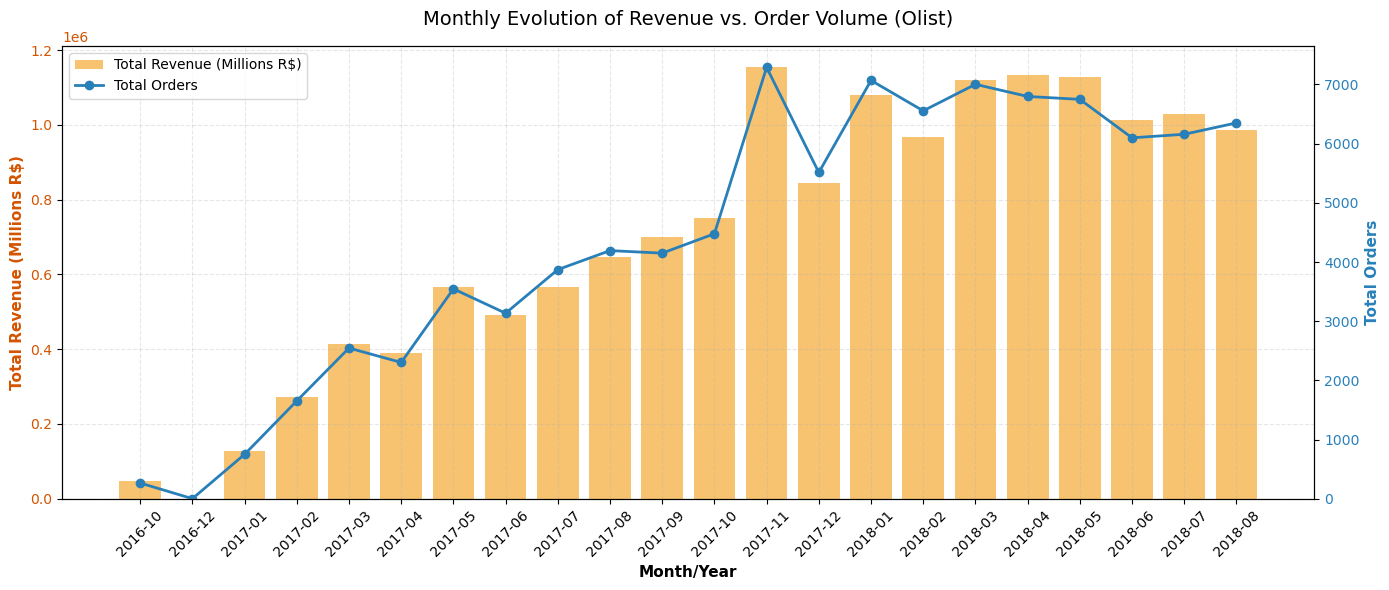

In [11]:
import matplotlib.pyplot as plt

df_vendas = vendas.DataFrame()

# Criar a figura
fig, ax1 = plt.subplots(figsize=(14, 6))

# Eixo 1 (Esquerda): Barras para Faturação
ax1.bar(
    df_vendas["mes_ano_venda"],
    df_vendas["total_faturado"],
    color="#f39c12",
    alpha=0.6,
    label="Total Revenue (Millions R$)",
)
ax1.set_xlabel("Month/Year", fontsize=11, fontweight="bold")
ax1.set_ylabel("Total Revenue (Millions R$)", color="#d35400", fontsize=11, fontweight="bold")
ax1.tick_params(axis="x", rotation=45)
ax1.tick_params(axis="y", labelcolor="#d35400")

# Eixo 2 (Direita): Linha para Volume de Pedidos
ax2 = ax1.twinx()
ax2.plot(
    df_vendas["mes_ano_venda"],
    df_vendas["total_pedidos"],
    color="#2980b9",
    marker="o",
    linewidth=2,
    label="Total Orders",
)
ax2.set_ylabel("Total Orders", color="#2980b9", fontsize=11, fontweight="bold")
ax2.tick_params(axis="y", labelcolor="#2980b9")
ax2.set_ylim(bottom=0)  # Força o zero na base
# Título e Ajustes Finais
plt.title(
    "Monthly Evolution of Revenue vs. Order Volume (Olist)",
    fontsize=14,
    pad=15,
)
ax1.grid(True, linestyle="--", alpha=0.3)  # Adiciona uma grelha suave para leitura

# Unificar Legendas num único bloco
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

plt.tight_layout()
plt.show()

In [13]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# 1. Converter os dados do SQL para DataFrame
df_vendas = vendas.DataFrame()

# 2. Criar figura com eixo secundário
fig = make_subplots(specs=[[{"secondary_y": True}]])

# 3. Adicionar as Barras (Faturação)
fig.add_trace(
    go.Bar(
        x=df_vendas["mes_ano_venda"],
        y=df_vendas["total_faturado"] / 1000000.0,
        name="Total Revenue (Millions R$)",
        marker_color="#f39c12",
        opacity=0.7,
    ),
    secondary_y=False,
)

# 4. Adicionar a Linha (Pedidos)
fig.add_trace(
    go.Scatter(
        x=df_vendas["mes_ano_venda"],
        y=df_vendas["total_pedidos"],
        name="Total Orders",
        mode="lines+markers",
        line=dict(color="#2980b9", width=3),
        marker=dict(size=7),
    ),
    secondary_y=True,
)

# 5. Formatar Títulos e Eixos (Forçando o zero na base)
fig.update_layout(
    title_text="<b>Monthly Evolution of Revenue vs. Order Volume (Olist)</b>",
    xaxis_title="Mês/Ano",
    template="plotly_white",
    hovermode="x unified",
    legend=dict(x=0.01, y=0.99),
)

fig.update_yaxes(
    title_text="Total Revenue (Millions R$)",
    rangemode="tozero",
    secondary_y=False,
)
fig.update_yaxes(
    title_text="Total Orders", rangemode="tozero", secondary_y=True
)

# 6. Guardar como HTML
fig.write_html("grafico_vendas_olist.html")
print("Gráfico guardado em 'grafico_vendas_olist.html'")

Gráfico guardado em 'grafico_vendas_olist.html'


In [34]:
%%sql
pagamentos <<
SELECT
    COALESCE(p.payment_type, 'Unknown') AS payment_type,
    COUNT(DISTINCT(p.order_id)) AS total_payments,
    SUM(p.payment_value) AS total_revenue_type,
    ROUND(
        (SUM(p.payment_value) / (SELECT SUM(payment_value) FROM payments)) * 100,2) AS pct_total_revenue,
    ROUND(
        AVG(CASE WHEN p.payment_type = 'credit_card' THEN p.payment_installments ELSE NULL END),1) AS average_installments
FROM payments p
JOIN vw_orders_cleaned o
    ON p.order_id = o.order_id
GROUP BY p.payment_type
ORDER BY pct_total_revenue DESC;


Running query in 'sqlite:///olist_ecommerce.db'

In [35]:
df_pagamentos = pagamentos.DataFrame()

df_pagamentos.head(4)


,payment_type,total_payments,total_revenue_type,pct_total_revenue,average_installments
0,credit_card,76505,12542084.19,78.34,3.5
1,boleto,19784,2869361.27,17.92,NaN
2,voucher,3866,379436.87,2.37,NaN
3,debit_card,1528,217989.79,1.36,NaN


In [37]:
import plotly.graph_objects as go

# Converter os dados SQL para DataFrame
df_pagamentos = pagamentos.DataFrame()

# Criar gráfico de barras com a percentagem
fig = go.Figure(
    go.Bar(
        x=df_pagamentos["payment_type"],
        y=df_pagamentos["pct_total_revenue"],
        text=[f"{v:.1f}%" for v in df_pagamentos["pct_total_revenue"]],
        textposition="auto",
        marker_color=["#2980b9", "#f39c12", "#2ecc71", "#e74c3c"],
    )
)

fig.update_layout(
    title_text="<b>Revenue Distribution by Payment Method (Olist)</b>",
    xaxis_title="Payment Method",
    yaxis_title="Pct of Total Revenue (%)",
    template="plotly_white",
)

# Guardar como HTML
fig.write_html("grafico_pagamentos_olist.html")
print("Gráfico guardado em 'grafico_pagamentos_olist.html'")

Gráfico guardado em 'grafico_pagamentos_olist.html'


In [8]:
%%sql
resultado_query <<
SELECT
    p.product_category_name_english,
    COUNT(DISTINCT oi.order_id) AS total_orders,
    ROUND(SUM(oi.price), 2) AS total_revenue,
    ROUND(AVG(r.review_score),2) AS average_review_score,
    ROUND((SUM(CASE WHEN r.review_score <= 2 THEN 1.0 ELSE 0.0 END) / COUNT(r.review_score) * 100), 2) AS pct_negative_reviews
FROM vw_reviews_cleaned r
JOIN vw_order_items_cleaned oi
    ON r.order_id = oi.order_id
JOIN vw_products_cleaned p
    ON oi.product_id = p.product_id
GROUP BY p.product_category_name_english
ORDER BY total_revenue DESC
LIMIT 10

Running query in 'sqlite:///olist_ecommerce.db'

In [10]:
import plotly.express as px

# Converter resultado SQL para DataFrame
df_top_cats = resultado_query.DataFrame()

# Gráfico de barras relacionando Receita e % Reviews Negativas
fig = px.bar(
    df_top_cats,
    x="product_category_name_english",
    y="total_revenue",
    color="pct_negative_reviews",
    color_continuous_scale="Reds",
    labels={
        "product_category_name_english": "Product Category",
        "total_revenue": "Total Revenue (Millions R$)",
        "pct_negative_reviews": "% Negative Reviews",
    },
    title="<b>Top Categorias por Receita vs. Taxa de Insatisfação do Cliente</b>",
)

fig.update_layout(template="plotly_white", xaxis_tickangle=-45)
fig.write_html("grafico_qualidade_categoria.html")

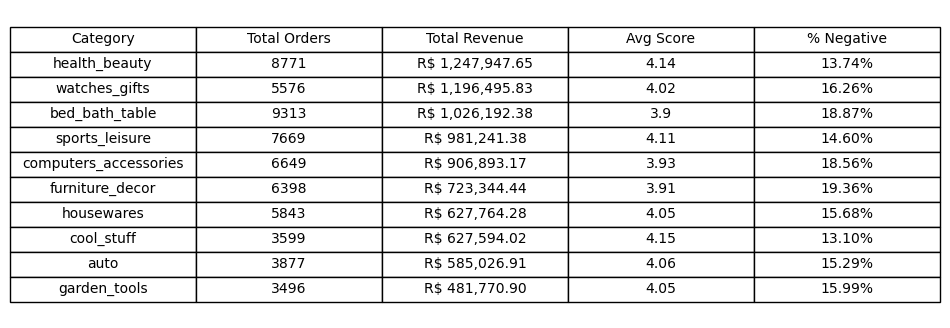

In [12]:
import matplotlib.pyplot as plt

# 1. Converter os dados para DataFrame
df_top = resultado_query.DataFrame()

# 2. Formatar os números para ficarem mais legíveis (ex: moeda e percentagens)
df_display = df_top.copy()
df_display["total_revenue"] = df_display["total_revenue"].apply(
    lambda x: f"R$ {x:,.2f}"
)
df_display["pct_negative_reviews"] = df_display["pct_negative_reviews"].apply(
    lambda x: f"{x:.2f}%"
)

# Rename das colunas para o relatório
df_display.columns = [
    "Category",
    "Total Orders",
    "Total Revenue",
    "Avg Score",
    "% Negative",
]

# 3. Criar a figura da tabela
fig, ax = plt.subplots(figsize=(10, 4))
ax.axis("off")  # Ocultar eixos do gráfico

# 4. Desenhar a tabela
tabla = ax.table(
    cellText=df_display.values,
    colLabels=df_display.columns,
    cellLoc="center",
    loc="center",
)

# Estilização
tabla.auto_set_font_size(False)
tabla.set_fontsize(10)
tabla.scale(1.2, 1.5)

# Guardar em alta resolução para o relatório
plt.savefig(
    "tabela_top_categorias.png", bbox_inches="tight", dpi=300, transparent=False
)
plt.show()